In [1]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [3]:
# --- 1. Load and Clean Data ---
# Loading directly from the provided Excel file
df = pd.read_excel("OnlineRetail.xlsx")

# Clean: Remove missing IDs and canceled/free orders
df = df.dropna(subset=['CustomerID'])
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Calculate total spend per line item
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

In [4]:
# --- 2. Calculate RFM (Recency, Frequency, Monetary) ---
# Create a snapshot date (1 day after the last transaction in the dataset)
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# Aggregate data to customer level
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency: Days since last purchase
    'InvoiceNo': 'nunique',                                  # Frequency: Total number of orders
    'TotalAmount': 'sum'                                     # Monetary: Total money spent
}).reset_index()

# Rename columns for clarity
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

In [5]:
# --- 3. Scale the Data ---
# ML algorithms calculate distance. We must scale so Monetary (thousands)
# doesn't overpower Frequency (single digits).
X = rfm[['Recency', 'Frequency', 'Monetary']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
# --- 4. PCA (Dimensionality Reduction) ---
pca = PCA(n_components=2)
rfm[['PCA1', 'PCA2']] = pca.fit_transform(X_scaled)

In [7]:
# --- 5. Clustering (K-Means & DBSCAN) ---
# K-Means: Forces customers into exactly 3 groups
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# DBSCAN: Density-based grouping, automatically finds anomalies (-1)
dbscan = DBSCAN(eps=0.5, min_samples=5)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

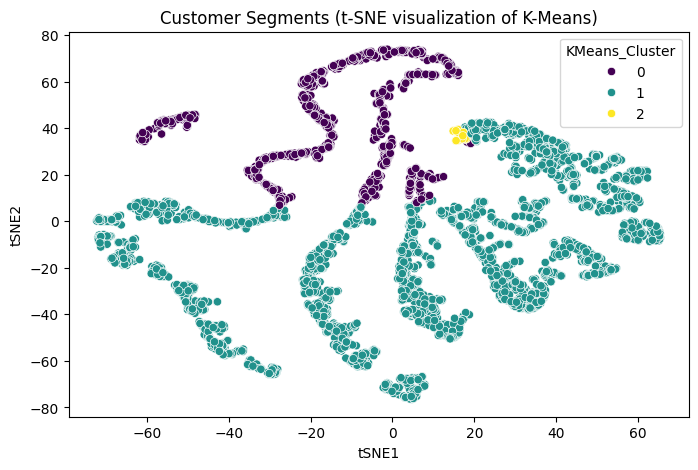

In [8]:
# --- 6. t-SNE Visualization ---
# t-SNE unwraps the complex multidimensional data into an easy-to-read 2D plot
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
rfm[['tSNE1', 'tSNE2']] = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='tSNE1', y='tSNE2',
    hue='KMeans_Cluster',
    palette='viridis',
    data=rfm
)
plt.title("Customer Segments (t-SNE visualization of K-Means)")
plt.show()

In [9]:
# --- 7. Derive Marketing Personas ---
cluster_summary = rfm.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean()
print("\nCluster Summary (Averages):")
print(cluster_summary)


Cluster Summary (Averages):
                   Recency  Frequency      Monetary
KMeans_Cluster                                     
0               247.106285   1.582255    631.424206
1                41.454180   4.672755   1855.942345
2                 6.038462  66.423077  85904.351538
